In [1]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
from IPython import display


In [2]:
import glob
import os
import cv2
os.environ['TRIDENT_BACKEND'] = 'tensorflow'

import trident as T
from trident import *
from trident.models import resnet

trident 0.7.4


Using TensorFlow backend.
Image Data Format: channels_last.
Image Channel Order: rgb.
1 Physical GPUs, 1 Logical GPUs


Opencv version:4.5.4-dev.


Tensorflow version:2.7.0.
executing_eagerly
use device:/gpu:0.


Pillow version:8.4.0.


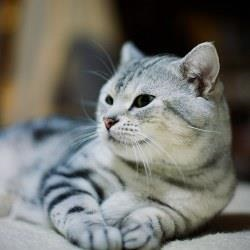

In [3]:
display.Image('cat.jpg')

In [4]:
resnet50=resnet.ResNet50(include_top=True,
             pretrained=True,
             input_shape=(224, 224,3),
             classes=1000)

model file is already existing, donnot need download again.
2049000 parameters have set untrainable
2049000 parameters have set trainable
/job:localhost/replica:0/task:0/device:GPU:0


In [5]:
resnet50.summary()

--------------------------------------------------------------------------------------------------------------------------------
          Layer (type)            Output Shape               Weight                            Bias      Param #   FLOPS #                  
conv1.conv  [Conv2d]                [None, 112, 112, 64]       'weight', [7, 7, 3, 64]                     9,408  134,865,920  
conv1.norm  [BatchNorm]             [None, 112, 112, 64]       'weight', [64]                    'bias', [64]  128  1,820,672  
conv1  [Conv2d_Block]               [None, 112, 112, 64]                                                   0  0  
maxpool  [MaxPool2d]                [None, 56, 56, 64]                                                     0  0  
layer1.0.0.conv  [Conv2d]           [None, 56, 56, 256]        'weight', [1, 1, 64, 256]                   16,384  469,747,712  
layer1.0.0.norm  [BatchNorm]        [None, 56, 56, 256]        'weight', [256]                   'bias', [256]  512  

ImageClassificationModel()

In [6]:
print(resnet50.infer_single_image('cat.jpg',5))

{  n02124075	埃及猫: (285, 0.94798034),  n02123045	虎斑猫: (281, 0.028914098),  n02123159	山猫: (282, 0.019102212),  n02128757	雪豹: (289, 0.0019819988),  n02127052	猞猁: (287, 0.00032747828) }


In [7]:
data_provider=T.load_examples_data('animals')
data_provider.image_transform_funcs=[
                     RandomCenterCrop((224,224),scale_range=(0.8,2)),
                     #原比例隨機縮放(正確縮放比例再乘上0.8~1.2之間隨機數)中央裁切至224,224
                     RandomAdjustGamma(gamma_range=(0.6,1.5)),
                     #隨機調整圖片明暗gamma 0.6~1.4之間
                     RandomAdjustContrast(value_range=(0.6, 1.5)),
                     #隨機調整圖片對比度
                     RandomTransform(rotation_range=20,zoom_range=0.1,shift_range=0.02,shear_range=0.02,random_flip=0.2),
                     GrayMixRGB(keep_prob=0.75),
                     SaltPepperNoise(prob=0.002),#椒鹽噪音                 
                     RandomGridMask(size_range=(224,224),max_d1=64,rotation_range=(10,30),keep_prob=0.6),
                     Normalize(127,128)] 

archive file is already existing, donnot need download again.
extraction is finished, donnot need extract again.
C:/Users/allan/.trident/datasets/examples_animals
['cat', 'chipmunk', 'dog', 'fox', 'giraffe', 'guinea pig', 'hyena', 'reindeer', 'sikadeer', 'squirrel', 'weasel', 'wolf']
C:/Users/allan/.trident/datasets/examples_animals/cat/*.*g
2766
C:/Users/allan/.trident/datasets/examples_animals/chipmunk/*.*g
2829
C:/Users/allan/.trident/datasets/examples_animals/dog/*.*g
3132
C:/Users/allan/.trident/datasets/examples_animals/fox/*.*g
3191
C:/Users/allan/.trident/datasets/examples_animals/giraffe/*.*g
3227
C:/Users/allan/.trident/datasets/examples_animals/guinea pig/*.*g
2970
C:/Users/allan/.trident/datasets/examples_animals/hyena/*.*g
2679
C:/Users/allan/.trident/datasets/examples_animals/reindeer/*.*g
3158
C:/Users/allan/.trident/datasets/examples_animals/sikadeer/*.*g
2857
C:/Users/allan/.trident/datasets/examples_animals/squirrel/*.*g
2551
C:/Users/allan/.trident/datasets/examples_

image


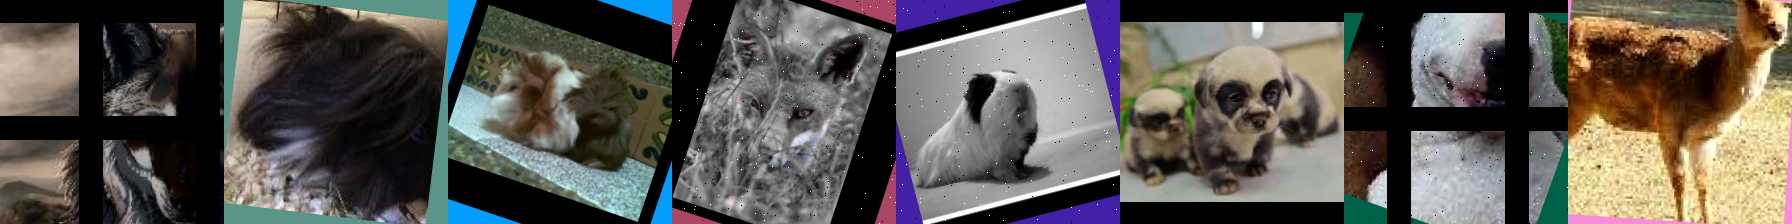

In [8]:
data_provider.preview_images()

In [9]:
images,labels=data_provider.next()
print(images.shape)

(8, 224, 224, 3)


In [10]:
resnet50=resnet.ResNet50(include_top=True,
             pretrained=True,
             input_shape=(224, 224,3),
             classes=12)
resnet50.with_optimizer(optimizer=AdaBelief,lr=1e-3,betas=(0.9, 0.999))\
    .with_loss(CrossEntropyLoss(auto_balance=True))\
    .with_metric(accuracy,name='accuracy')\
    .with_metric(accuracy,topk=3,name='top3_accuracy')\
    .with_regularizer('l2',reg_weight=1e-5)\
    .with_model_save_path('Models/finetune_resnet50.pth')\
    .with_learning_rate_scheduler(CosineLR(period=12000,unit='batch',max_lr=1e-3, min_lr=1e-6))\
   

model file is already existing, donnot need download again.
2049000 parameters have set untrainable
/job:localhost/replica:0/task:0/device:GPU:0
CrossEntropyLoss( output: Tensor[(None,)] , target: Tensor[(None,)] ) -> loss: Tensor[(None,)]  
accuracy( output: Tensor[(None,)] , target: Tensor[(None,)] , topk: int =1, axis: int =-1, ignore_index: int =-100, exclude_mask: bool =False) -> output: Tensor[(None,)]  
top3_accuracy( output: Tensor[(None,)] , target: Tensor[(None,)] , topk: int =1, axis: int =-1, ignore_index: int =-100, exclude_mask: bool =False) -> output: Tensor[(None,)]  


ImageClassificationModel(
  (_losses): <trident.optims.tensorflow_losses.CrossEntropyLoss object at 0x000001AA14F359B0>
  (_metrics): <function accuracy at 0x000001A914C9C620>
  (_metrics): functools.partial(<function accuracy at 0x000001A914C9C620>, topk=3)
  (loss_weights): 1.0
  (_regs): <function l2_reg at 0x000001A914C9C2F0>
)

data_feed for resnet50 :
{
    "axis": "axis",
    "exclude_mask": "exclude_mask",
    "ignore_index": "ignore_index",
    "output": "output",
    "target": "label",
    "topk": "topk",
    "x": "image"
}
build
Start retrive label class distribution for auto-balance in loss function.


100%|███████████████████████████████████████████████████████████████████████| 35407/35407 [00:00<00:00, 1133162.33it/s]

{ CrossEntropyLoss: 5.348, l2_reg_Loss: 6.883e-04, total_losses: 5.349 }
resnet50  Step: 787ms    | Loss: 4.845 | accuracy: 10.000% , top3_accuracy: 25.000%  | lr: 1.000e-03  | epoch: 0  ( 5/2951 )
resnet50  Step: 288ms    | Loss: 4.427 | accuracy: 5.000% , top3_accuracy: 26.667%  | lr: 1.000e-03  | epoch: 0  ( 10/2951 )
resnet50  Step: 270ms    | Loss: 5.519 | accuracy: 6.667% , top3_accuracy: 15.000%  | lr: 1.000e-03  | epoch: 0  ( 15/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   49°C  16% | 4861 /6144.0 MB  79.12%
resnet50  Step: 250ms    | Loss: 4.739 | accuracy: 11.667% , top3_accuracy: 28.333%  | lr: 1.000e-03  | epoch: 0  ( 20/2951 )
resnet50  Step: 252ms    | Loss: 5.119 | accuracy: 10.000% , top3_accuracy: 21.667%  | lr: 1.000e-03  | epoch: 0  ( 25/2951 )
resnet50  Step: 265ms    | Loss: 4.571 | accuracy: 6.667% , top3_accuracy: 30.000%  | lr: 1.000e-03  | epoch: 0  ( 30/2951 )
resnet50  Step: 268ms    | Loss: 4.456 | accuracy: 13.333% , top3_accuracy: 28.333%  

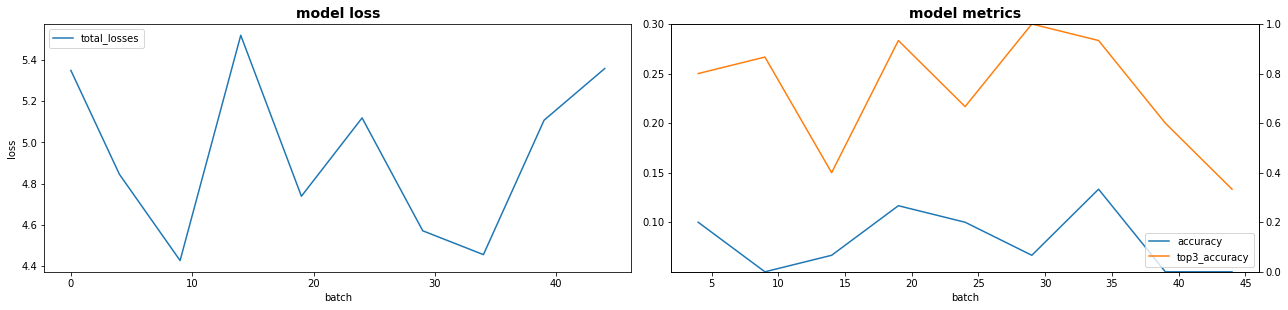

resnet50  Step: 291ms    | Loss: 5.803 | accuracy: 8.333% , top3_accuracy: 18.333%  | lr: 1.000e-03  | epoch: 0  ( 50/2951 )
resnet50  Step: 270ms    | Loss: 5.213 | accuracy: 6.667% , top3_accuracy: 25.000%  | lr: 1.000e-03  | epoch: 0  ( 55/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   52°C  11% | 4861 /6144.0 MB  79.12%
resnet50  Step: 265ms    | Loss: 4.401 | accuracy: 10.000% , top3_accuracy: 26.667%  | lr: 9.999e-04  | epoch: 0  ( 60/2951 )
resnet50  Step: 249ms    | Loss: 5.441 | accuracy: 1.667% , top3_accuracy: 21.667%  | lr: 9.999e-04  | epoch: 0  ( 65/2951 )
resnet50  Step: 249ms    | Loss: 4.847 | accuracy: 15.000% , top3_accuracy: 26.667%  | lr: 9.999e-04  | epoch: 0  ( 70/2951 )
resnet50  Step: 244ms    | Loss: 5.318 | accuracy: 13.333% , top3_accuracy: 21.667%  | lr: 9.999e-04  | epoch: 0  ( 75/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   53°C  20% | 4861 /6144.0 MB  79.12%
resnet50  Step: 259ms    | Loss: 4.029 | accuracy: 16.667% , top3_a

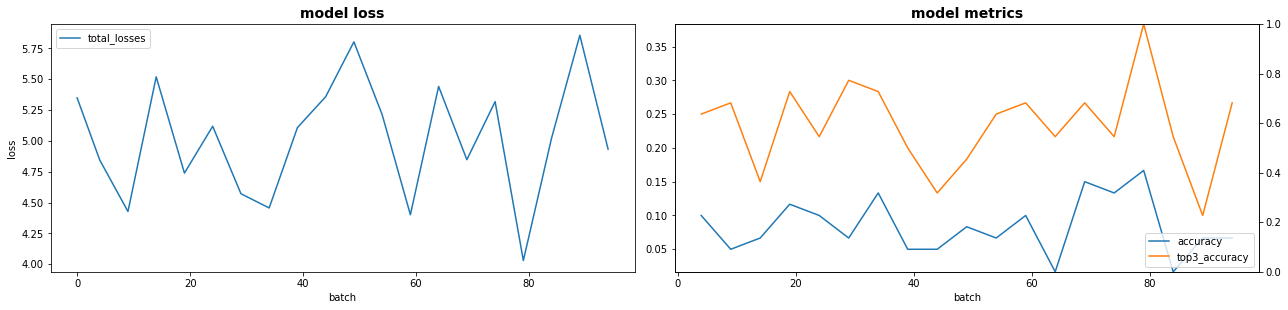

resnet50  Step: 488ms    | Loss: 4.814 | accuracy: 5.000% , top3_accuracy: 25.000%  | lr: 9.998e-04  | epoch: 0  ( 100/2951 )
resnet50  Step: 538ms    | Loss: 4.843 | accuracy: 11.667% , top3_accuracy: 30.000%  | lr: 9.998e-04  | epoch: 0  ( 105/2951 )
resnet50  Step: 394ms    | Loss: 4.253 | accuracy: 10.000% , top3_accuracy: 30.000%  | lr: 9.998e-04  | epoch: 0  ( 110/2951 )
resnet50  Step: 648ms    | Loss: 5.218 | accuracy: 5.000% , top3_accuracy: 18.333%  | lr: 9.998e-04  | epoch: 0  ( 115/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   57°C  20% | 4861 /6144.0 MB  79.12%
resnet50  Step: 449ms    | Loss: 4.187 | accuracy: 10.000% , top3_accuracy: 35.000%  | lr: 9.998e-04  | epoch: 0  ( 120/2951 )
resnet50  Step: 455ms    | Loss: 4.632 | accuracy: 8.333% , top3_accuracy: 26.667%  | lr: 9.997e-04  | epoch: 0  ( 125/2951 )
resnet50  Step: 403ms    | Loss: 5.100 | accuracy: 8.333% , top3_accuracy: 16.667%  | lr: 9.997e-04  | epoch: 0  ( 130/2951 )
resnet50  Step: 448ms    

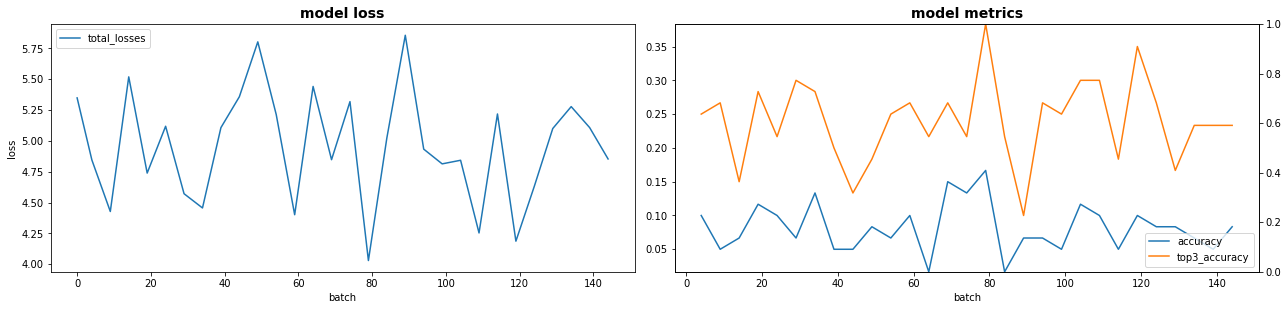

resnet50  Step: 402ms    | Loss: 5.120 | accuracy: 6.667% , top3_accuracy: 18.333%  | lr: 9.996e-04  | epoch: 0  ( 150/2951 )
resnet50  Step: 383ms    | Loss: 5.755 | accuracy: 3.333% , top3_accuracy: 13.333%  | lr: 9.996e-04  | epoch: 0  ( 155/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   59°C  22% | 4861 /6144.0 MB  79.12%
resnet50  Step: 415ms    | Loss: 5.738 | accuracy: 6.667% , top3_accuracy: 10.000%  | lr: 9.996e-04  | epoch: 0  ( 160/2951 )
resnet50  Step: 400ms    | Loss: 5.876 | accuracy: 8.333% , top3_accuracy: 21.667%  | lr: 9.995e-04  | epoch: 0  ( 165/2951 )
resnet50  Step: 458ms    | Loss: 4.688 | accuracy: 8.333% , top3_accuracy: 20.000%  | lr: 9.995e-04  | epoch: 0  ( 170/2951 )
resnet50  Step: 419ms    | Loss: 5.098 | accuracy: 5.000% , top3_accuracy: 18.333%  | lr: 9.995e-04  | epoch: 0  ( 175/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   58°C  14% | 4861 /6144.0 MB  79.12%
resnet50  Step: 432ms    | Loss: 4.849 | accuracy: 10.000% , top

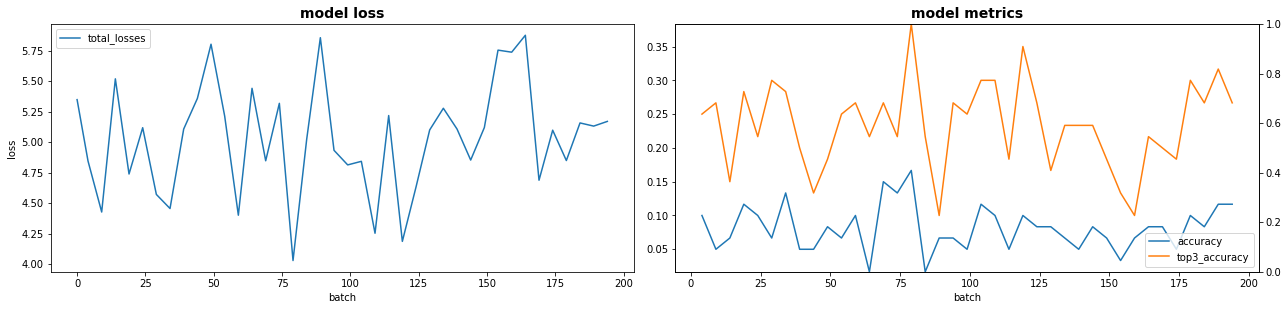

resnet50  Step: 435ms    | Loss: 4.872 | accuracy: 15.000% , top3_accuracy: 28.333%  | lr: 9.993e-04  | epoch: 0  ( 200/2951 )
resnet50  Step: 478ms    | Loss: 4.982 | accuracy: 10.000% , top3_accuracy: 18.333%  | lr: 9.993e-04  | epoch: 0  ( 205/2951 )
resnet50  Step: 474ms    | Loss: 5.184 | accuracy: 8.333% , top3_accuracy: 26.667%  | lr: 9.993e-04  | epoch: 0  ( 210/2951 )
resnet50  Step: 393ms    | Loss: 5.091 | accuracy: 6.667% , top3_accuracy: 15.000%  | lr: 9.992e-04  | epoch: 0  ( 215/2951 )
[0]  NVIDIA GeForce GTX 1660 Ti with Max-Q Design |   54°C  13% | 4861 /6144.0 MB  79.12%
resnet50  Step: 389ms    | Loss: 4.627 | accuracy: 10.000% , top3_accuracy: 23.333%  | lr: 9.992e-04  | epoch: 0  ( 220/2951 )


In [11]:
plan=TrainingPlan()\
    .add_training_item(resnet50)\
    .with_data_loader(data_provider)\
    .repeat_epochs(5)\
    .with_batch_size(12)\
    .print_progress_scheduling(5,unit='batch')\
    .print_gpu_utilization(20)\
    .save_model_scheduling(100,unit='batch')\
    .display_loss_metric_curve_scheduling(50,unit='batch',imshow=True)\
    .start_now()